# Phase 2 - Data Preprocessing and Six-Hour Warning Target Construction

**Objective: direct multiclass classification** of the highest experimental wave-warning category reached at the next two three-hourly timestamps. We do not train a regression model. `future_max_wave_height` is an intermediate label-construction diagnostic, never a regression training target or input feature.

Run cells manually from top to bottom in VS Code using the project `.venv` kernel. This notebook is supplied **unexecuted** and writes no files. It reads the original CSV, validates it, constructs labels in memory, compares experimental threshold candidates, and proposes chronological partitions. It performs no filling, scaling, SMOTE, feature selection, feature engineering, model training or tuning.

**No thresholds are finalized here.** Current/modelled significant wave heights and experimental categories are not official coastal warnings. The maximum below samples only `t+3h` and `t+6h`; it is not the maximum individual wave height during a continuously observed six-hour period.

## 1. Load the source CSV

The relative path works from either `notebooks/` or the project root. Loading creates an in-memory DataFrame; the source file is never overwritten. No state from the EDA notebook is required.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

data_path = Path("../data/udupi_wave_wind_2015_2024.csv")
if not data_path.is_file():
    data_path = Path("data/udupi_wave_wind_2015_2024.csv")
if not data_path.is_file():
    raise FileNotFoundError("Run from notebooks/ or the project root; the historical CSV is required.")

df = pd.read_csv(data_path, float_precision="round_trip")
source_columns = df.columns.tolist()
print(f"Loaded {len(df):,} rows and {len(df.columns)} columns")
display(df.head())

Loaded 29,224 rows and 20 columns


,timestamp,latitude,longitude,VHM0,VHM0_SW1,VHM0_SW2,VHM0_WW,VMDR,VMDR_SW1,VMDR_SW2,VMDR_WW,VTM01_SW1,VTM01_SW2,VTM01_WW,VTM02,VTM10,VTPK,eastward_wind,northward_wind,wind_speed
0,2015-01-01 00:00:00+00:00,13.4,74.599998,0.60,0.32,0.23,0.00,245.21,194.34,209.16,213.64,9.12,19.18,0.00,4.46,8.00,19.48,0.363307,0.706901,0.794796
1,2015-01-01 03:00:00+00:00,13.4,74.599998,0.57,0.31,0.26,0.00,239.12,193.46,209.12,145.02,8.96,18.49,0.00,4.66,8.62,19.02,0.563214,0.442098,0.716003
2,2015-01-01 06:00:00+00:00,13.4,74.599998,0.56,0.31,0.27,0.00,235.00,193.34,208.65,216.28,8.86,18.17,0.00,4.81,9.04,19.45,3.602809,0.997492,3.738345
3,2015-01-01 09:00:00+00:00,13.4,74.599998,0.57,0.30,0.29,0.15,233.51,211.54,189.86,249.71,16.71,9.40,1.85,4.29,8.99,19.07,4.851309,0.933394,4.940285
4,2015-01-01 12:00:00+00:00,13.4,74.599998,0.59,0.30,0.29,0.05,233.21,207.88,189.76,276.55,17.15,9.25,1.38,4.28,8.77,18.74,4.215613,-0.653205,4.265920


## 2. Validate schema, UTC timestamps and source measurements

Checks are intentionally strict for this known CSV. Parsing invalid timestamps to `NaT` is used only to identify issues; any such issue stops the notebook before labels are constructed. Numeric measurements are not coerced, filled, clipped or dropped. Sorting changes row order in memory only.

In [2]:
expected_columns = [
    "timestamp", "latitude", "longitude", "VHM0", "VHM0_SW1", "VHM0_SW2", "VHM0_WW",
    "VMDR", "VMDR_SW1", "VMDR_SW2", "VMDR_WW", "VTM01_SW1", "VTM01_SW2", "VTM01_WW",
    "VTM02", "VTM10", "VTPK", "eastward_wind", "northward_wind", "wind_speed",
]
if set(df.columns) != set(expected_columns) or df.columns.duplicated().any():
    raise ValueError(f"Unexpected schema. Missing: {set(expected_columns) - set(df.columns)}; extra: {set(df.columns) - set(expected_columns)}")

parsed_times = pd.to_datetime(df["timestamp"], utc=True, errors="coerce")
invalid_timestamp_count = int(parsed_times.isna().sum())
if invalid_timestamp_count:
    display(df.loc[parsed_times.isna()])
    raise ValueError(f"{invalid_timestamp_count} invalid timestamps; inspect the source before continuing.")
df["timestamp"] = parsed_times
was_chronological = df["timestamp"].is_monotonic_increasing
duplicate_count = int(df["timestamp"].duplicated().sum())
if duplicate_count:
    display(df.loc[df["timestamp"].duplicated(keep=False)])
    raise ValueError("Duplicate timestamps make future labels ambiguous; no rows were removed.")
df = df.sort_values("timestamp").reset_index(drop=True)

measurement_columns = [column for column in source_columns if column != "timestamp"]
non_numeric = [column for column in measurement_columns if not pd.api.types.is_numeric_dtype(df[column])]
if non_numeric:
    raise ValueError(f"Non-numeric measurements require investigation: {non_numeric}")
missing_by_column = df.isna().sum()
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_count": missing_by_column}))
if missing_by_column.any():
    raise ValueError("Source values are missing. No imputation or row removal has been performed.")
if not np.isfinite(df[measurement_columns].to_numpy()).all():
    raise ValueError("Nonfinite source measurements found; investigate before constructing labels.")

,dtype,missing_count
timestamp,"datetime64[us, UTC]",0
latitude,float64,0
longitude,float64,0
VHM0,float64,0
VHM0_SW1,float64,0
VHM0_SW2,float64,0
VHM0_WW,float64,0
VMDR,float64,0
VMDR_SW1,float64,0
VMDR_SW2,float64,0


### Continuity and physical consistency

Check the complete requested interval, including both boundaries. Zero partition heights/periods can represent an absent partition and are not automatically deleted. Negative heights/periods, invalid directions, inconsistent coordinates or speed arithmetic stop processing. The wind-component magnitude check is a broad sanity check, not a warning criterion.

In [3]:
expected_times = pd.date_range("2015-01-01 00:00", "2024-12-31 21:00", freq="3h", tz="UTC").as_unit("ns")
actual_times = pd.DatetimeIndex(df["timestamp"]).as_unit("ns")
missing_times = expected_times.difference(actual_times)
unexpected_times = actual_times.difference(expected_times)
irregular_intervals = df["timestamp"].diff().iloc[1:].ne(pd.Timedelta(hours=3))

if len(missing_times) or len(unexpected_times) or irregular_intervals.any():
    display(pd.DataFrame({"missing_timestamp": missing_times}))
    display(pd.DataFrame({"unexpected_timestamp": unexpected_times}))
    raise ValueError("Missing/off-grid timestamps or irregular intervals prevent reliable positional target construction.")

height_period_columns = [column for column in df if column.startswith(("VHM", "VTM", "VTP"))]
direction_columns = [column for column in df if column.startswith("VMDR")]
if df[height_period_columns].lt(0).any().any():
    raise ValueError("Negative source heights or periods; no measurements were changed.")
if any(not df[column].between(0, 360).all() for column in direction_columns):
    raise ValueError("Wave directions outside 0-360 degrees need investigation.")
reference_coordinates = df[["latitude", "longitude"]].drop_duplicates()
if len(reference_coordinates) != 1 or not np.allclose(
    reference_coordinates.iloc[0].to_numpy(), [13.399999618530273, 74.5999984741211], rtol=0, atol=1e-10
):
    raise ValueError("Unexpected or changing offshore reference coordinates.")
if df[["eastward_wind", "northward_wind"]].abs().gt(100).any().any():
    raise ValueError("Implausible wind component magnitude needs investigation.")
if not np.allclose(df["wind_speed"], np.hypot(df["eastward_wind"], df["northward_wind"]), rtol=1e-10, atol=1e-12):
    raise ValueError("Stored wind speed does not match the component magnitude.")

validation_summary = pd.Series({
    "source_rows": len(df), "source_columns": len(source_columns),
    "start_UTC": df["timestamp"].min(), "end_UTC": df["timestamp"].max(),
    "timezone": str(df["timestamp"].dt.tz), "frequency": "3h",
    "original_order_chronological": was_chronological,
    "duplicate_timestamps": duplicate_count, "missing_measurements": int(missing_by_column.sum()),
    "missing_expected_timestamps": len(missing_times), "irregular_intervals": int(irregular_intervals.sum()),
    "VHM0_min_m": df["VHM0"].min(), "VHM0_max_m": df["VHM0"].max(),
    "reference_latitude": df["latitude"].iloc[0], "reference_longitude": df["longitude"].iloc[0],
})
display(validation_summary.to_frame("validation_result"))

,validation_result
source_rows,29224
source_columns,20
start_UTC,2015-01-01 00:00:00+00:00
end_UTC,2024-12-31 21:00:00+00:00
timezone,UTC
frequency,3h
original_order_chronological,True
duplicate_timestamps,0
missing_measurements,0
missing_expected_timestamps,0


## 3. Construct the intermediate six-hour future maximum

Future measurements are legitimate when defining supervised **labels**: they describe the outcome we will later predict. They cause leakage if they enter input features, fitted transformations or earlier partitions' labels. They must never be supplied to a classifier as predictors.

Before using shifts, explicitly verify that the next two observations occur at exactly `t+3h` and `t+6h`. `skipna=False` requires both heights; the final two rows lack a complete future horizon and are excluded only from the in-memory labeled dataset. They remain available in the unchanged source data to complete earlier labels.

In [4]:
future_3h_time = df["timestamp"].shift(-1)
future_6h_time = df["timestamp"].shift(-2)
exact_3h = future_3h_time.eq(df["timestamp"] + pd.Timedelta(hours=3))
exact_6h = future_6h_time.eq(df["timestamp"] + pd.Timedelta(hours=6))
if not exact_3h.iloc[:-1].all() or not exact_6h.iloc[:-2].all():
    raise ValueError("Future rows do not correspond to exact +3h/+6h timestamps.")

future_3h = df["VHM0"].shift(-1)
future_6h = df["VHM0"].shift(-2)
future_maximum = pd.concat([future_3h, future_6h], axis=1).max(axis=1, skipna=False)
complete_horizon = exact_3h & exact_6h & future_3h.notna() & future_6h.notna()
if not complete_horizon.iloc[:-2].all() or complete_horizon.iloc[-2:].any():
    raise ValueError("Unexpected incomplete future horizons; inspect timestamps and values.")

df["future_max_wave_height"] = future_maximum.where(complete_horizon)
labeled = df.loc[complete_horizon].copy()
horizon_excluded_count = int((~complete_horizon).sum())
print(f"Usable complete-horizon observations: {len(labeled):,}")
print(f"Excluded final observations: {horizon_excluded_count}")

Usable complete-horizon observations: 29,222
Excluded final observations: 2


In [5]:
verification = pd.DataFrame({
    "timestamp": df["timestamp"], "current_VHM0": df["VHM0"],
    "next_3h_timestamp": future_3h_time, "next_3h_height": future_3h,
    "next_6h_timestamp": future_6h_time, "next_6h_height": future_6h,
    "future_max_wave_height": df["future_max_wave_height"],
})
display(verification.head(8))
display(verification.tail(4))

# Source measurements remain separate from future-derived diagnostics; no feature matrix is built.
source_measurement_columns = [column for column in source_columns if column not in ("timestamp", "latitude", "longitude")]
future_diagnostic_columns = ["future_max_wave_height"]
if set(source_measurement_columns).intersection(future_diagnostic_columns):
    raise ValueError("A future-derived diagnostic entered the source measurement list.")
print("Do not use as inputs:", future_diagnostic_columns, "or any temporary future-height/time series.")

,timestamp,current_VHM0,next_3h_timestamp,next_3h_height,next_6h_timestamp,next_6h_height,future_max_wave_height
0,2015-01-01 00:00:00+00:00,0.60,2015-01-01 03:00:00+00:00,0.57,2015-01-01 06:00:00+00:00,0.56,0.57
1,2015-01-01 03:00:00+00:00,0.57,2015-01-01 06:00:00+00:00,0.56,2015-01-01 09:00:00+00:00,0.57,0.57
2,2015-01-01 06:00:00+00:00,0.56,2015-01-01 09:00:00+00:00,0.57,2015-01-01 12:00:00+00:00,0.59,0.59
3,2015-01-01 09:00:00+00:00,0.57,2015-01-01 12:00:00+00:00,0.59,2015-01-01 15:00:00+00:00,0.60,0.60
4,2015-01-01 12:00:00+00:00,0.59,2015-01-01 15:00:00+00:00,0.60,2015-01-01 18:00:00+00:00,0.61,0.61
5,2015-01-01 15:00:00+00:00,0.60,2015-01-01 18:00:00+00:00,0.61,2015-01-01 21:00:00+00:00,0.61,0.61
6,2015-01-01 18:00:00+00:00,0.61,2015-01-01 21:00:00+00:00,0.61,2015-01-02 00:00:00+00:00,0.60,0.61
7,2015-01-01 21:00:00+00:00,0.61,2015-01-02 00:00:00+00:00,0.60,2015-01-02 03:00:00+00:00,0.59,0.60


,timestamp,current_VHM0,next_3h_timestamp,next_3h_height,next_6h_timestamp,next_6h_height,future_max_wave_height
29220,2024-12-31 12:00:00+00:00,0.52,2024-12-31 15:00:00+00:00,0.56,2024-12-31 18:00:00+00:00,0.57,0.57
29221,2024-12-31 15:00:00+00:00,0.56,2024-12-31 18:00:00+00:00,0.57,2024-12-31 21:00:00+00:00,0.58,0.58
29222,2024-12-31 18:00:00+00:00,0.57,2024-12-31 21:00:00+00:00,0.58,NaT,NaN,NaN
29223,2024-12-31 21:00:00+00:00,0.58,NaT,NaN,NaT,NaN,NaN


Do not use as inputs: ['future_max_wave_height'] or any temporary future-height/time series.


## 4. Define chronological 70/10/20 partitions before comparing thresholds

Time-series forecasts must be evaluated on later observations, not randomly shuffled neighbors. Adjacent samples share sea-state persistence and overlapping future horizons.

Use `floor(0.70*N)` training rows and `floor(0.10*N)` validation rows; assign the remainder to testing. These **nominal** boundaries are calculated from all complete-horizon labeled observations, not calendar years. Remove training rows whose `t+6h` reaches the nominal validation start, and validation rows whose horizon reaches the nominal test start. Equality reaches the next partition and is excluded. Do not move boundaries after purging.

The final test labels may use the final raw observations even though those observations cannot themselves form complete labeled rows. No test row is used to fit anything. Future historical features must use only measurements available at or before their prediction timestamp; legitimate earlier history can cross an input partition boundary without reaching forward.

In [6]:
n_labeled = len(labeled)
n_train_nominal = int(np.floor(0.70 * n_labeled))
n_validation_nominal = int(np.floor(0.10 * n_labeled))
validation_position = n_train_nominal
test_position = n_train_nominal + n_validation_nominal
nominal_partitions = {
    "Training": labeled.iloc[:validation_position].copy(),
    "Validation": labeled.iloc[validation_position:test_position].copy(),
    "Testing": labeled.iloc[test_position:].copy(),
}
if any(part.empty for part in nominal_partitions.values()):
    raise ValueError("Not enough labeled rows for the requested partitions.")
next_partition_starts = {
    "Training": nominal_partitions["Validation"]["timestamp"].iloc[0],
    "Validation": nominal_partitions["Testing"]["timestamp"].iloc[0],
}
partitions = {}
boundary_parts = []
for name, part in nominal_partitions.items():
    if name in next_partition_starts:
        keep = (part["timestamp"] + pd.Timedelta(hours=6)).lt(next_partition_starts[name])
        boundary_parts.append(part.loc[~keep, ["timestamp", "future_max_wave_height"]].assign(partition=name))
        partitions[name] = part.loc[keep].copy()
    else:
        partitions[name] = part.copy()

boundary_exclusions = pd.concat(boundary_parts, ignore_index=True)
n_retained = sum(len(part) for part in partitions.values())
print("Nominal validation start:", next_partition_starts["Training"])
print("Nominal test start:", next_partition_starts["Validation"])
print("Boundary rows excluded:", len(boundary_exclusions))
display(boundary_exclusions)

Nominal validation start: 2021-12-31 21:00:00+00:00
Nominal test start: 2023-01-01 03:00:00+00:00
Boundary rows excluded: 4


,timestamp,future_max_wave_height,partition
0,2021-12-31 15:00:00+00:00,0.47,Training
1,2021-12-31 18:00:00+00:00,0.47,Training
2,2022-12-31 21:00:00+00:00,0.54,Validation
3,2023-01-01 00:00:00+00:00,0.54,Validation


In [7]:
split_rows = []
for name, part in partitions.items():
    nominal = nominal_partitions[name]
    split_rows.append({
        "partition": name, "nominal_rows": len(nominal),
        "nominal_percent_of_labeled": len(nominal) / n_labeled * 100,
        "boundary_rows_excluded": len(nominal) - len(part), "usable_rows": len(part),
        "start_UTC": part["timestamp"].min(), "end_UTC": part["timestamp"].max(),
        "latest_target_timestamp_UTC": part["timestamp"].max() + pd.Timedelta(hours=6),
        "usable_percent_of_labeled": len(part) / n_labeled * 100,
        "percent_of_retained_rows": len(part) / n_retained * 100,
    })
    if name in next_partition_starts and not (part["timestamp"] + pd.Timedelta(hours=6)).lt(next_partition_starts[name]).all():
        raise ValueError(f"{name} labels cross into the next partition.")
if partitions["Testing"]["timestamp"].max() + pd.Timedelta(hours=6) > df["timestamp"].max():
    raise ValueError("A test target extends beyond available source observations.")
if n_retained + len(boundary_exclusions) != n_labeled:
    raise ValueError("Split accounting does not match the labeled dataset.")

split_summary = pd.DataFrame(split_rows).set_index("partition")
display(split_summary)
train = partitions["Training"]
validation = partitions["Validation"]
test = partitions["Testing"]

,nominal_rows,nominal_percent_of_labeled,boundary_rows_excluded,usable_rows,start_UTC,end_UTC,latest_target_timestamp_UTC,usable_percent_of_labeled,percent_of_retained_rows
partition,,,,,,,,,
Training,20455,69.998631,2,20453,2015-01-01 00:00:00+00:00,2021-12-31 12:00:00+00:00,2021-12-31 18:00:00+00:00,69.991787,70.001369
Validation,2922,9.999316,2,2920,2021-12-31 21:00:00+00:00,2022-12-31 18:00:00+00:00,2023-01-01 00:00:00+00:00,9.992471,9.993839
Testing,5845,20.002053,0,5845,2023-01-01 03:00:00+00:00,2024-12-31 15:00:00+00:00,2024-12-31 21:00:00+00:00,20.002053,20.004792


## 5. Analyze the future-maximum distribution

Show full-labeled descriptive statistics as requested, alongside training-only statistics. **Full-period summaries include the held-out years and are descriptive only; do not use them to select thresholds or tune models.** The training distribution is the decision-development view. Requested test class counts later in the notebook similarly reveal prevalence, not permission to optimize against the test set.

This numeric future maximum is a label-construction diagnostic, not a regression learning objective. No model is fitted to it.

,Full labeled period (descriptive only),Training only (threshold development)
count,29222.000000,20453.000000
mean,1.100630,1.115300
std,0.739339,0.744119
min,0.300000,0.300000
median / 50th percentile,0.750000,0.760000
75%,1.470000,1.520000
80%,1.710000,1.760000
85%,1.960000,2.010000
90%,2.270000,2.290000
95%,2.700000,2.690000


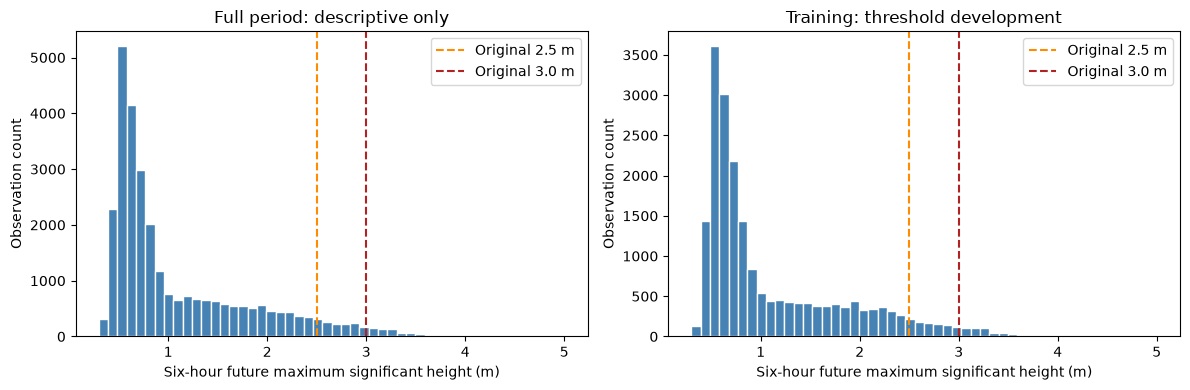

In [8]:
percentiles = [0.50, 0.75, 0.80, 0.85, 0.90, 0.95, 0.97, 0.99]
target_statistics = pd.concat({
    "Full labeled period (descriptive only)": labeled["future_max_wave_height"].describe(percentiles=percentiles),
    "Training only (threshold development)": train["future_max_wave_height"].describe(percentiles=percentiles),
}, axis=1).rename(index={"50%": "median / 50th percentile"})
display(target_statistics)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, title in [
    (axes[0], labeled["future_max_wave_height"], "Full period: descriptive only"),
    (axes[1], train["future_max_wave_height"], "Training: threshold development"),
]:
    ax.hist(values, bins=50, color="steelblue", edgecolor="white")
    ax.axvline(2.5, color="darkorange", linestyle="--", label="Original 2.5 m")
    ax.axvline(3.0, color="firebrick", linestyle="--", label="Original 3.0 m")
    ax.set(title=title, xlabel="Six-hour future maximum significant height (m)", ylabel="Observation count")
    ax.legend()
fig.tight_layout()
plt.show()

## 6. Original provisional thresholds: comparison baseline only

For every pair `(lower, upper)`, use Class 0 below `lower`, Class 1 from `lower` through `upper` inclusive, and Class 2 strictly above `upper`. Exactly 2.5 m and exactly 3.0 m are both Elevated for the original pair. This small helper makes candidate comparisons consistent; it does not select final thresholds.

In [9]:
class_names = {0: "Normal", 1: "Elevated", 2: "High"}

def candidate_classes(heights, lower, upper):
    if not 0 <= lower < upper or not np.isfinite([lower, upper]).all():
        raise ValueError("Thresholds must be finite, nonnegative and increasing.")
    if not np.isfinite(heights).all() or heights.lt(0).any():
        raise ValueError("Complete finite nonnegative future heights are required.")
    return pd.Series(
        np.select([heights.lt(lower), heights.le(upper)], [0, 1], default=2),
        index=heights.index, name="candidate_class", dtype="int64",
    )

original_rows = []
for scope, part in [("Full labeled period (descriptive only)", labeled), ("Training only", train)]:
    labels = candidate_classes(part["future_max_wave_height"], 2.5, 3.0)
    counts = labels.value_counts().reindex([0, 1, 2], fill_value=0)
    for number, count in counts.items():
        original_rows.append({"scope": scope, "class": number, "category": class_names[number],
                              "count": int(count), "percent": count / len(part) * 100})
original_balance = pd.DataFrame(original_rows).set_index(["scope", "class", "category"])
display(original_balance)

count    percent
scope                                  class category                  
Full labeled period (descriptive only) 0     Normal    27157  92.933406
                                       1     Elevated   1300   4.448703
                                       2     High        765   2.617891
Training only                          0     Normal    19031  93.047475
                                       1     Elevated    872   4.263433
                                       2     High        550   2.689092

## 7. Compare a small, predeclared set of experimental pairs

Compare `(2.5, 3.0)`, `(2.25, 2.75)` and `(2.0, 2.5)` metres. The latter two are modest fixed-height sensitivity checks, not quantile-balanced classes, recommendations or scientifically validated safety levels. The printed training distribution can inform the later discussion; no adaptive threshold selection is performed here.

Lower boundaries can provide more Elevated/High training examples but redefine the event and may weaken its physical meaning. Higher boundaries can describe more extreme conditions yet leave few independent events to learn from. Counts of adjacent three-hourly rows overstate the number of independent storm events. Physical justification, temporal stability and sufficient examples must all be considered before deciding.

**Candidate balance and monthly/yearly comparisons below use training data only.** Validation may be consulted later if necessary. No thresholds are finalized, even if one candidate looks statistically convenient.

In [10]:
candidate_pairs = {
    "Original 2.5 / 3.0 m": (2.5, 3.0),
    "Sensitivity 2.25 / 2.75 m": (2.25, 2.75),
    "Sensitivity 2.0 / 2.5 m": (2.0, 2.5),
}
candidate_summary_rows = []
for candidate, (lower, upper) in candidate_pairs.items():
    labels = candidate_classes(train["future_max_wave_height"], lower, upper)
    counts = labels.value_counts().reindex([0, 1, 2], fill_value=0)
    row = {"candidate": candidate, "lower_m": lower, "upper_m": upper,
           "minority_class_size": int(counts.min()), "minority_class_percent": counts.min() / len(train) * 100}
    for number in [0, 1, 2]:
        row[f"{class_names[number]}_count"] = int(counts[number])
        row[f"{class_names[number]}_percent"] = counts[number] / len(train) * 100
    candidate_summary_rows.append(row)
candidate_summary = pd.DataFrame(candidate_summary_rows).set_index("candidate")
display(candidate_summary)

,lower_m,upper_m,minority_class_size,minority_class_percent,Normal_count,Normal_percent,Elevated_count,Elevated_percent,High_count,High_percent
candidate,,,,,,,,,,
Original 2.5 / 3.0 m,2.50,3.00,550,2.689092,19031,93.047475,872,4.263433,550,2.689092
Sensitivity 2.25 / 2.75 m,2.25,2.75,921,4.503007,18278,89.365863,1254,6.131130,921,4.503007
Sensitivity 2.0 / 2.5 m,2.00,2.50,1398,6.835183,17329,84.725957,1726,8.438860,1398,6.835183


In [11]:
for candidate, (lower, upper) in candidate_pairs.items():
    labels = candidate_classes(train["future_max_wave_height"], lower, upper)
    display(Markdown(f"### {candidate}: training-only seasonality"))
    for grouping_name, groups in [
        ("month", train["timestamp"].dt.month),
        ("year", train["timestamp"].dt.year),
    ]:
        counts = pd.crosstab(groups.rename(grouping_name), labels).reindex(columns=[0, 1, 2], fill_value=0)
        if grouping_name == "month":
            counts = counts.reindex(range(1, 13), fill_value=0)
        totals = counts.sum(axis=1)
        summary = pd.DataFrame({
            "total_observations": totals,
            "Elevated_count": counts[1], "High_count": counts[2],
            "Elevated_percent_within_period": counts[1].div(totals.replace(0, np.nan)).mul(100),
            "High_percent_within_period": counts[2].div(totals.replace(0, np.nan)).mul(100),
        })
        print(f"Training distribution by {grouping_name} (percentages use each period's total):")
        display(summary)

### Original 2.5 / 3.0 m: training-only seasonality

Training distribution by month (percentages use each period's total):


,total_observations,Elevated_count,High_count,Elevated_percent_within_period,High_percent_within_period
month,,,,,
1,1736,0,0,0.000000,0.000000
2,1584,0,0,0.000000,0.000000
3,1736,0,0,0.000000,0.000000
4,1680,0,0,0.000000,0.000000
5,1736,11,21,0.633641,1.209677
6,1680,239,212,14.226190,12.619048
7,1736,445,211,25.633641,12.154378
8,1736,138,95,7.949309,5.472350
9,1680,25,0,1.488095,0.000000


Training distribution by year (percentages use each period's total):


,total_observations,Elevated_count,High_count,Elevated_percent_within_period,High_percent_within_period
year,,,,,
2015,2920,66,65,2.260274,2.226027
2016,2928,105,85,3.586066,2.903005
2017,2920,129,23,4.417808,0.787671
2018,2920,164,153,5.616438,5.239726
2019,2920,160,78,5.479452,2.671233
2020,2928,146,44,4.986339,1.502732
2021,2917,102,102,3.496743,3.496743


...

### Sensitivity 2.0 / 2.5 m: training-only seasonality

Training distribution by month (percentages use each period's total):


,total_observations,Elevated_count,High_count,Elevated_percent_within_period,High_percent_within_period
month,,,,,
1,1736,0,0,0.000000,0.000000
2,1584,0,0,0.000000,0.000000
3,1736,2,0,0.115207,0.000000
4,1680,2,0,0.119048,0.000000
5,1736,37,32,2.131336,1.843318
6,1680,470,438,27.976190,26.071429
7,1736,612,649,35.253456,37.384793
8,1736,480,230,27.649770,13.248848
9,1680,114,24,6.785714,1.428571


Training distribution by year (percentages use each period's total):


,total_observations,Elevated_count,High_count,Elevated_percent_within_period,High_percent_within_period
year,,,,,
2015,2920,169,131,5.787671,4.486301
2016,2928,240,189,8.196721,6.454918
2017,2920,323,146,11.061644,5.000000
2018,2920,279,311,9.554795,10.650685
2019,2920,312,230,10.684932,7.876712
2020,2928,208,188,7.103825,6.420765
2021,2917,195,203,6.684950,6.959205


## 8. Partition class distributions: diagnostic audit, not threshold selection

The following table shows training, validation **and testing** class distributions for every candidate, as requested. Test prevalence is therefore visible; do not treat this as a blind test-prevalence analysis. **Do not use test counts, the full-period histogram, or full-period quantiles to select thresholds, features or models.** No selection or optimization code follows. If thresholds are selected later, document the physical/training rationale and any validation consultation before model evaluation.

In [12]:
partition_class_rows = []
for candidate, (lower, upper) in candidate_pairs.items():
    for partition_name, part in partitions.items():
        labels = candidate_classes(part["future_max_wave_height"], lower, upper)
        counts = labels.value_counts().reindex([0, 1, 2], fill_value=0)
        for number, count in counts.items():
            partition_class_rows.append({
                "candidate": candidate, "partition": partition_name,
                "class": number, "category": class_names[number],
                "count": int(count), "percent_within_partition": count / len(part) * 100,
            })
partition_class_distributions = pd.DataFrame(partition_class_rows).set_index(["candidate", "partition", "class", "category"])
display(partition_class_distributions)

count  \
candidate                 partition  class category          
Original 2.5 / 3.0 m      Training   0     Normal    19031   
                                     1     Elevated    872   
                                     2     High        550   
                          Validation 0     Normal     2674   
                                     1     Elevated    153   
                                     2     High         93   
                          Testing    0     Normal     5448   
                                     1     Elevated    275   
                                     2     High        122   
Sensitivity 2.25 / 2.75 m Training   0     Normal    18278   
                                     1     Elevated   1254   
                                     2     High        921   
                          Validation 0     Normal     2613   
                                     1     Elevated    131   
                                     2     High        176   
                          Testing    0     Normal     5318   
                                     1     Elevated    275   
                                     2     High        252   
Sensitivity 2.0 / 2.5 m   Training   0     Normal    17329   
                                     1     Elevated   1726   
                                     2     High       1398   
                          Validation 0     Normal     2564   
                                     1     Elevated    114   
                                     2     High        242   
                          Testing    0     Normal     5115   
                                     1     Elevated    346   
                                     2     High        384   

                                                     percent_within_partition  
candidate                 partition  class category                            
Original 2.5 / 3.0 m      Training   0     Normal                   93.047475  
                                     1     Elevated                  4.263433  
                                     2     High                      2.689092  
                          Validation 0     Normal                   91.575342  
                                     1     Elevated                  5.239726  
                                     2     High                      3.184932  
                          Testing    0     Normal                   93.207870  
                                     1     Elevated                  4.704876  
                                     2     High                      2.087254  
Sensitivity 2.25 / 2.75 m Training   0     Normal                   89.365863  
                                     1     Elevated                  6.131130  
                                     2     High                      4.503007  
                          Validation 0     Normal                   89.486301  
                                     1     Elevated                  4.486301  
                                     2     High                      6.027397  
                          Testing    0     Normal                   90.983747  
                                     1     Elevated                  4.704876  
                                     2     High                      4.311377  
Sensitivity 2.0 / 2.5 m   Training   0     Normal                   84.725957  
                                     1     Elevated                  8.438860  
                                     2     High                      6.835183  
                          Validation 0     Normal                   87.808219  
                                     1     Elevated                  3.904110  
                                     2     High                      8.287671  
                          Testing    0     Normal                   87.510693  
                                     1     Elevated                  5.919589  
              

## 9. Results summary generated when you run the notebook

The next cell renders observed findings as Markdown. No outputs or findings have been precomputed by executing this notebook. All derived data remain in memory and no threshold candidate becomes a finalized target column.

In [13]:
full_original = candidate_classes(labeled["future_max_wave_height"], 2.5, 3.0).value_counts().reindex([0, 1, 2], fill_value=0)
train_original = candidate_classes(train["future_max_wave_height"], 2.5, 3.0).value_counts().reindex([0, 1, 2], fill_value=0)
full_balance_text = "; ".join(f"{class_names[k]}: {int(full_original[k]):,} ({full_original[k] / len(labeled) * 100:.2f}%)" for k in [0, 1, 2])
train_balance_text = "; ".join(f"{class_names[k]}: {int(train_original[k]):,} ({train_original[k] / len(train) * 100:.2f}%)" for k in [0, 1, 2])
split_text = "; ".join(f"{name}: {len(part):,} rows ({len(part) / n_labeled * 100:.2f}% of complete-horizon rows), {part['timestamp'].min()} to {part['timestamp'].max()}" for name, part in partitions.items())
h = labeled["future_max_wave_height"]
display(Markdown(f"""
### Phase 2 findings

- **Data quality:** all validation checks passed on {len(df):,} source observations; no missing measurements, duplicate timestamps or irregular three-hour intervals. Sorting was performed in memory; no measurements were filled, clipped or repaired.
- **Complete labels:** {len(labeled):,} observations have both exact future measurements. {horizon_excluded_count} final rows lack complete horizons; {len(boundary_exclusions)} additional boundary rows are purged, leaving {n_retained:,} partitioned samples.
- **Future maximum, full-period descriptive summary:** min {h.min():.3f} m; max {h.max():.3f} m; mean {h.mean():.3f} m; median {h.median():.3f} m; sample std {h.std():.3f} m. Requested percentiles and training-only statistics appear above. These heights are label diagnostics, not regression training targets.
- **Original 2.5 / 3.0 m balance (full period, descriptive only):** {full_balance_text}.
- **Original balance (training only):** {train_balance_text}.
- **Candidate trade-offs:** the training-only table shows class counts, percentages and smallest class for each fixed pair; monthly/yearly tables show temporal concentration. More examples do not establish coastal-warning validity. No candidate is selected.
- **Chronological split:** {split_text}. Nominal proportions are 70/10/20; usable proportions change slightly after boundary exclusion.
- **Still undecided:** final experimental thresholds and physical justification; validation consultation if needed; historical feature definitions and incomplete-history policy. Do not use test statistics for these decisions.
"""))


### Phase 2 findings

- **Data quality:** all validation checks passed on 29,224 source observations; no missing measurements, duplicate timestamps or irregular three-hour intervals. Sorting was performed in memory; no measurements were filled, clipped or repaired.
- **Complete labels:** 29,222 observations have both exact future measurements. 2 final rows lack complete horizons; 4 additional boundary rows are purged, leaving 29,218 partitioned samples.
- **Future maximum, full-period descriptive summary:** min 0.300 m; max 5.000 m; mean 1.101 m; median 0.750 m; sample std 0.739 m. Requested percentiles and training-only statistics appear above. These heights are label diagnostics, not regression training targets.
- **Original 2.5 / 3.0 m balance (full period, descriptive only):** Normal: 27,157 (92.93%); Elevated: 1,300 (4.45%); High: 765 (2.62%).
- **Original balance (training only):** Normal: 19,031 (93.05%); Elevated: 872 (4.26%); High: 550 (2.69%).
- **Candidate trade-offs:** the training-only table shows class counts, percentages and smallest class for each fixed pair; monthly/yearly tables show temporal concentration. More examples do not establish coastal-warning validity. No candidate is selected.
- **Chronological split:** Training: 20,453 rows (69.99% of complete-horizon rows), 2015-01-01 00:00:00+00:00 to 2021-12-31 12:00:00+00:00; Validation: 2,920 rows (9.99% of complete-horizon rows), 2021-12-31 21:00:00+00:00 to 2022-12-31 18:00:00+00:00; Testing: 5,845 rows (20.00% of complete-horizon rows), 2023-01-01 03:00:00+00:00 to 2024-12-31 15:00:00+00:00. Nominal proportions are 70/10/20; usable proportions change slightly after boundary exclusion.
- **Still undecided:** final experimental thresholds and physical justification; validation consultation if needed; historical feature definitions and incomplete-history policy. Do not use test statistics for these decisions.


## Review checkpoint before Phase 3

Discuss the displayed data-quality findings, complete-horizon sample count, future-height distribution, original class imbalance, training-only candidate seasonality and the purged chronological split before implementing features.

No final warning thresholds, regression targets for training, fitted transforms, features, models, tuning or operational warnings have been produced. The original CSV, acquisition script and completed EDA notebook remain unchanged. Notebooks 03, 04 and 05 remain placeholders. Future features must be causal and must exclude every future-height/time diagnostic and candidate label from their input columns.